# Multiclass Logistic Regression — Which Iris Flower Is It?

The insurance model answered a **yes / no** question (2 classes). But lots of problems have **more than two** answers:

- Is this review 😞 negative, 😐 neutral, or 😀 positive?
- Is this transaction low, medium, or high risk?
- Which of 3 flower species is this?

When each sample belongs to **exactly one of 3+ categories**, that's **multiclass classification**. The good news: `LogisticRegression` handles it out of the box — same tool, more classes.

We'll use the classic **Iris** dataset: measurements of 150 flowers from **3 species** (*setosa*, *versicolor*, *virginica*).

## The data

Iris is so famous it ships **built into scikit-learn** — no file to download. `load_iris(as_frame=True)` hands us a ready-made pandas DataFrame.

Four measurements (in cm) per flower, plus the species we want to predict:
- `sepal_length`, `sepal_width`
- `petal_length`, `petal_width`
- `species` — one of `setosa`, `versicolor`, `virginica`

In [12]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame.copy()
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [13]:
# tidy up the column names and turn the numeric target into species names
df.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'target']
df.head()

,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [14]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [15]:
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
df.head()

,sepal_length,sepal_width,petal_length,petal_width,target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [16]:
df = df.drop(columns=['target'])
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
# how many of each species? (nicely balanced: 50 each)
df.species.value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

## Look at the data first

Plot **petal length vs petal width**, coloured by species. Notice that *setosa* sits off on its own (easy to spot 🌱), while *versicolor* and *virginica* **overlap** a bit — those two are where the model will make most of its mistakes.

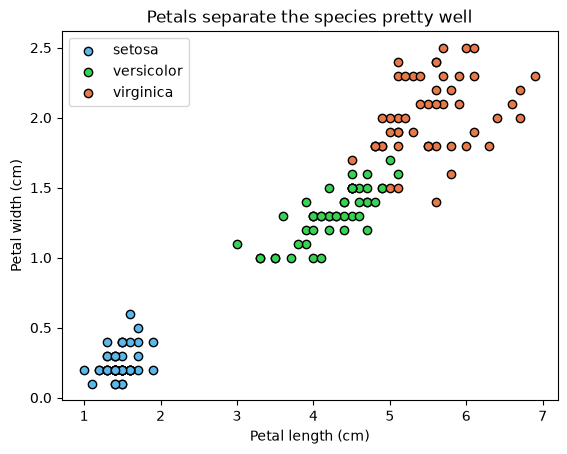

In [3]:
import matplotlib.pyplot as plt

colors = {'setosa': '#5BB8E8', 'versicolor': '#39D353', 'virginica': '#E8794B'}
for name, group in df.groupby('species'):
    plt.scatter(group.petal_length, group.petal_width,
                color=colors[name], edgecolor='k', label=name)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Petals separate the species pretty well")
plt.legend()
plt.show()

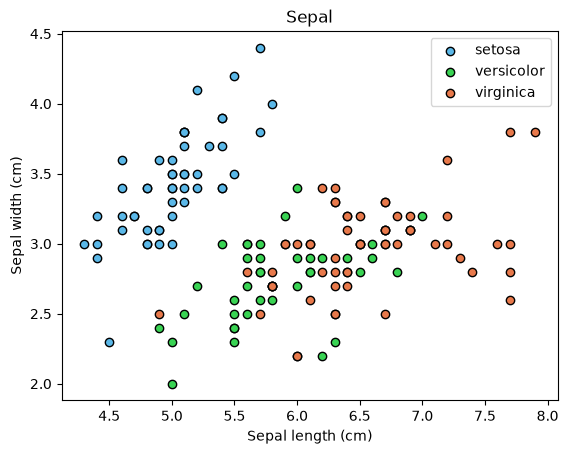

In [18]:
import matplotlib.pyplot as plt

colors = {'setosa': '#5BB8E8', 'versicolor': '#39D353', 'virginica': '#E8794B'}
for name, group in df.groupby('species'):
    plt.scatter(group.sepal_length, group.sepal_width,
                color=colors[name], edgecolor='k', label=name)
plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.title("Sepal")
plt.legend()
plt.show()

## Step 1 — Features (X) and target (y)

Use all four measurements to predict the species.

In [4]:
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
X = df[features]
y = df.species

print("X shape:", X.shape)
print("Classes:", list(y.unique()))

X shape: (150, 4)
Classes: ['setosa', 'versicolor', 'virginica']


## Step 2 — Train / test split

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=11
)

print("Training rows:", X_train.shape[0])
print("Testing rows: ", X_test.shape[0])

Training rows: 120
Testing rows:  30


## Step 3 — Train the multiclass model

Exactly the same `LogisticRegression` as before. Under the hood it fits one set of weights per class and picks the class with the **highest probability** — but you don't have to do anything special. (`max_iter=200` just gives it a little extra room to converge.)

In [6]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

print("Learned classes:", model.classes_)

Learned classes: ['setosa' 'versicolor' 'virginica']


## Step 4 — Predict

`predict()` returns the species name directly. Let's check the first few test flowers against their true labels.

In [7]:
y_pred = model.predict(X_test)

compare = pd.DataFrame({'actual': y_test.values, 'predicted': y_pred})
compare.head(10)

,actual,predicted
0,virginica,virginica
1,virginica,virginica
2,virginica,versicolor
3,versicolor,versicolor
4,virginica,virginica
5,setosa,setosa
6,versicolor,versicolor
7,setosa,setosa
8,setosa,setosa
9,versicolor,versicolor


You can also peek at the **probabilities** for a single flower — the model spreads its confidence across all three species and picks the biggest.

In [8]:
sample = X_test.iloc[[0]]
probs = model.predict_proba(sample)[0]
for species, p in zip(model.classes_, probs):
    print(f"{species:12s} -> {p:.2f}")
print("\nPredicted:", model.predict(sample)[0])

setosa       -> 0.00
versicolor   -> 0.09
virginica    -> 0.91

Predicted: virginica


## Step 5 — Accuracy

In [9]:
accuracy = model.score(X_test, y_test)
print(f"Accuracy on the test set: {accuracy:.2f}")

Accuracy on the test set: 0.93


## Step 6 — Confusion matrix

With 3 classes the confusion matrix is a **3×3 grid**. Each row is the *true* species, each column is what the model *predicted*. The **diagonal** = correct; anything off the diagonal shows exactly **which species get mixed up** with which.

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
print(cm)

[[ 9  0  0]
 [ 0 10  0]
 [ 0  2  9]]


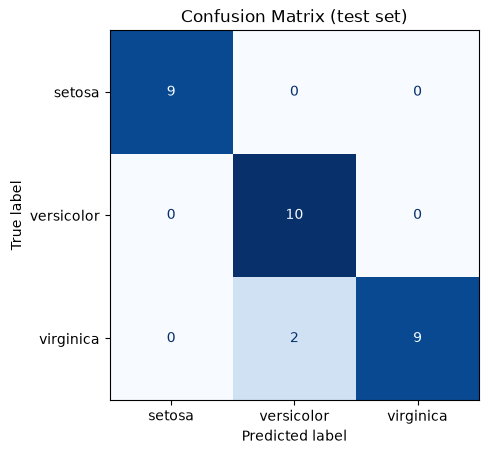

In [11]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap='Blues', colorbar=False)
plt.title('Confusion Matrix (test set)')
plt.show()

As predicted from the scatter plot, **setosa** is nailed every time, and any confusion is between **versicolor** and **virginica** — the two species whose petals overlapped.

## Step 7 — Classification report

Accuracy is one number for the whole model. The **classification report** breaks performance down **per species**:

- **precision** — of everything the model *called* species X, how much really was X?
- **recall** — of all the *actual* species X, how much did the model catch?
- **f1-score** — a single balance of precision and recall
- **support** — how many test flowers of that species there were

In [12]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         9
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.82      0.90        11

    accuracy                           0.93        30
   macro avg       0.94      0.94      0.94        30
weighted avg       0.94      0.93      0.93        30



## Step 8 — Predict a brand-new flower

A botanist hands you a flower: petals **1.4 × 0.2 cm**, sepals **5.1 × 3.5 cm**. What species is it?

In [13]:
new_flower = pd.DataFrame([{
    'sepal_length': 5.1, 'sepal_width': 3.5,
    'petal_length': 1.4, 'petal_width': 0.2
}])
print("Predicted species:", model.predict(new_flower)[0])

Predicted species: setosa


## Recap
- **Multiclass** = predict **one** label out of **3+** categories
- `LogisticRegression` handles multiclass automatically — no code changes needed
- `model.predict_proba` spreads confidence across all classes; the biggest one wins
- A **confusion matrix** (N×N) shows *which* classes get confused with each other
- A **classification report** gives **precision / recall / f1** per class — far richer than a single accuracy number
- Same recipe scales to sentiment (neg/neutral/pos), risk tiers, image labels, and more